# Building an engineering agent for PLE: lab journal

A living record of how our entry to the *Physical-Engineering's Last Exam* competition is built:
what we measured, what we observed, and why each part of the harness exists. It is the source for
the competition write-up.

Every number below is read from the run tracker (`research/runs.jsonl`) when the notebook runs.
The story so far, in order: **(1)** a cloud VM so we can judge exactly, **(2)** a split of the
dev set in two, **(3)** a very simple naive test with just a model.

## Write-up tracker

The final upload is written from this notebook, against the competition's judging criteria
(from the Kaggle page; the fifth criterion was cut off in our copy and is still to be added).
Status: `todo` / `draft` / `done`. Update the table in `research/build_journal.py`, then rebuild.

| # | Criterion (points) | What judges look for | What we have / still need | Status |
|---|---|---|---|---|
| 1 | **Insight & failure analysis** (25) | Something non-obvious; real dev-set failures; controlled ablations ("we added X, score went A to B"); ideas that failed | Near miss in section 5; lab log. Need: one-change-at-a-time ladder runs, failures read task by task, failed ideas written down | draft |
| 2 | **Engineering reasoning** (25) | One concrete dev task walked through, our agent's trajectory against a licensed engineer's workflow: where it held up, where it took shortcuts, which domain skills separated pass from fail | Need: keep the full trajectory of each run (not just scores) and pick one task | todo |
| 3 | **Cross-model generalizability** (15) | All 29 dev tasks with at least two models, ideally across families; which changes help every model, which only one; how model choice shifts accuracy and token cost; comparison table in the write-up; one target `google-cloud/<id>` committed in `submission.yaml` for Stage 2 | Rung 0 runs two models on half A only. Need: every rung on 2+ models, a final pass over all 29 (half B needs a stated reason), and the single target model chosen | todo |
| 4 | **Efficiency & scaling** (20) | Dev score against compute budget (calls, tokens, runtime or parallel verification attempts); where accuracy plateaus; remaining headroom | Tracker stores tokens and seconds per task. Need: a score-vs-budget chart per rung, and at least one budget knob to vary (for example verification attempts) | todo |
| 5 | *(not yet seen)* | | Add from the Kaggle page | todo |

Also needed, from our own plan: the evaluation setup (section 2), the split and hold-out
discipline (section 3), the final architecture (`docs/architecture.md`,
`docs/design-decisions.md`) and how to reproduce (`infra/`).

## 1. The problem

PLE has 85 real engineering tasks: structural, civil, electrical and mechanical. Each runs in an
isolated container with the project's files and up to 6 hours, and asks for a real deliverable: a
calculation package, a coordinated IFC model, a review memo. Tasks are graded `0`-`1` by
programmatic checks, by an LLM judge against an expert rubric, or both.

An entry is a **harness**, the code that drives a model through each task, paired with one of the
Google-sponsored models. The best stock setup on the public leaderboard (Gemini 4 Neon with
Google's own agent) scores **0.507** on the 56 hidden tasks: about half the available points.

## 2. An evaluation environment in a cloud VM

**Why.** We want to judge our harness *exactly* as the competition does: its own task images,
its own graders, the same protocol. That needs Docker with real memory (some tasks run app
servers and need up to 16 GB), and a model endpoint for both the harness and the judge.

**What we set up**

* One VM (`ple-runner`, spot `n2-standard-32`, 250 GB, Docker + Harbor) in our own Google Cloud
  project, running the competition's `eval/run.py` unchanged. It powers itself off after 30 idle
  minutes and after 24 h, so a forgotten VM cannot run up a bill.
* The competition's model proxy on the VM, calling Vertex AI as the VM's own service account (no
  keys stored).
* A budget of 600 DKK a month with alerts, and a **hard cap** that switches billing off at 100 %.
* Control from a cloud session, with no laptop: a GitHub Actions workflow starts the VM, runs a
  job script on it and reads the log back. Google trusts GitHub's identity for this one
  repository (workload identity federation), so no keys are stored.

**Why not the laptop.** Docker Desktop on the 8 GB Mac had 3.8 GB, too little for the larger
tasks, and the laptop later broke.

**Caveat on the judge.** The leaderboard judges rubric tasks with Claude Opus 5.5. Our project
has no Vertex quota for it (three increase requests were auto-denied), so development runs use
Gemini 4 Neon as judge. Judged scores are therefore *approximate*; we only compare runs that
share a judge, and the tracker refuses to merge runs with different judges.

## 3. Splitting the dev set in two

**A split we don't cheat on.** The 29 public dev tasks are split in two. We develop only on
**half A** (15 tasks). **Half B** (14 tasks) is held out and run rarely, to check that what helps
on A carries over to tasks we have never looked at; the tracker refuses to record a half-B run
without a stated reason. Five tasks we had studied in detail before splitting were placed in A by
construction; the rest were assigned at random (fixed seed), balanced by grading type.

In [1]:
import json, pathlib, sys
import pandas as pd
import matplotlib.pyplot as plt

HERE = pathlib.Path.cwd()
sys.path.insert(0, str(HERE))
import tracker

split = tracker.load_split()
rows = [{"half": h, "task": t, **{k: split["tasks"][t][k] for k in ("grading", "domain")}}
        for h in ("A", "B") for t in split[h]]
tasks = pd.DataFrame(rows)
print(f"seed {split['seed']} · {split['method']}")
pd.crosstab(tasks["grading"], tasks["half"], margins=True, margins_name="total")

seed 20261124 · already-studied tasks fixed in A; the rest assigned at random per grading type


half,A,B,total
grading,,,
checks,6,6,12
checks-judge,2,1,3
rubric,7,7,14
total,15,14,29


In [2]:
tasks[tasks.half == "A"][["task", "grading", "domain"]].reset_index(drop=True)

,task,grading,domain
0,data-hall-mep-routing,checks,Mechanical engineering
1,fire-test-validation-memo,rubric,Mechanical engineering
2,eor-review-corrections,checks-judge,Structural engineering
3,data-center-site-model,checks,Civil engineering
4,solar-witness-test-package,rubric,Electrical engineering
5,frame-extension-method,checks,Civil engineering
6,fire-solve-convergence,rubric,Mechanical engineering
7,les-mesh-resolution,rubric,Mechanical engineering
8,division-26-specifications,checks,Electrical engineering
9,wind-diaphragm-shear,checks,Structural engineering


## 4. Rung 0: a naive test with just a model

**Design.** One model call, no tools, no agent loop. Before the call the harness (not the model)
turns the task's files into plain text and pastes them after the task text; images are listed by
name only. The model answers once; files it writes as marked blocks in its answer are saved in
the task container, and the rest of the answer is the final message. It cannot open files or run
anything. It lives in `harnesses/naive/`.

**Why start here.** It is the floor every later rung is measured against. If a tool loop does not
beat it, the loop is not earning its cost.

**Known limits, by design.** It can only write text files (no xlsx, docx or images), and it never
checks its own work. We expect it to fail on those tasks, and *which* tasks it fails is the point.

**The comparison.** The same harness with two models: Gemini 3.8 Flash (the "bad" model) and
Gemini 4 Neon (the "better" one), over all of half A, judged by Gemini 4 Neon.

In [3]:
runs = tracker.load_runs()
overview = pd.DataFrame([{
    "run": r["run_id"], "label": r["label"], "model": r["harness"]["model"],
    "half": r["half"], "judge": tracker.judge_name(r.get("judge_model")), "score": round(tracker.score(r)["score"], 3),
    "measured": f"{tracker.score(r)['n_measured']}/{tracker.score(r)['n_tasks']}",
    "run date": (r["source"].get("run_date") or "")[:10],
} for r in runs])
overview

,run,label,model,half,judge,score,measured,run date
0,run-000,reference: official template (Pi + Claude Opus...,google-cloud/claude-opus-5-5,A,?,0.543,15/15,2026-10-20


In [4]:
from IPython.display import display
INK, MUTED, GRID, SURFACE = "#1f1f1e", "#6b6a64", "#e7e6e1", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834"]  # categorical slots 1-2, validated (CVD and contrast)

def task_frame(run):
    s = tracker.score(run)
    return pd.DataFrame([{"task": t, "grading": split["tasks"][t]["grading"], "score": sc}
                         for t, sc, _ in s["rows"]])

def plot_runs(run_ids, title):
    chosen = [r for r in runs if r["run_id"] in run_ids]
    base = task_frame(chosen[0]).sort_values("score")
    order = list(base["task"])
    fig, ax = plt.subplots(figsize=(8.5, 0.36 * len(order) + 1.4), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)
    y = range(len(order))
    for i, run in enumerate(chosen):
        f = task_frame(run).set_index("task").loc[order]
        label = f"{run['run_id']} · {tracker.score(run)['score']:.3f}"
        if len(chosen) == 1:
            ax.barh(list(y), f["score"], height=0.55, color=SERIES[0], label=label)
            for yi, sc in zip(y, f["score"]):
                if sc == 0:
                    ax.text(0.005, yi, "0", color=MUTED, fontsize=9, va="center")
        else:
            ax.scatter(f["score"], list(y), s=46, color=SERIES[i], zorder=3, label=label,
                       edgecolors=SURFACE, linewidths=2)
    mean = tracker.score(chosen[0])["score"]
    ax.axvline(mean, color=MUTED, lw=1, ls=(0, (3, 3)))
    ax.text(mean, len(order) - 0.4, f" mean {mean:.3f}", color=MUTED, fontsize=9, va="bottom")
    ax.set_yticks(list(y), [f"{t}  ({split['tasks'][t]['grading']})" for t in order], color=INK, fontsize=9)
    ax.set_xlim(0, 1.0); ax.set_xlabel("task score", color=MUTED, fontsize=9)
    ax.tick_params(axis="x", colors=MUTED, labelsize=9); ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for side in ("top", "right", "left"): ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.set_title(title, loc="left", color=INK, fontsize=11, pad=10)
    if len(chosen) > 1:
        ax.legend(frameon=False, fontsize=9, loc="lower right")
    fig.tight_layout()
    return fig

### Rung 0 results

Filled in from the tracker once the runs are recorded (`rung 0` in the run label).

In [5]:
rung0 = [r for r in runs if r["label"].lower().startswith("rung 0")]
if rung0:
    display(plot_runs([r["run_id"] for r in rung0], "Rung 0: one model call, score per task on half A"))
    print(overview[overview["label"].str.lower().str.startswith("rung 0")].to_string(index=False))
else:
    print("No rung-0 run is recorded yet.")

No rung-0 run is recorded yet.


## 5. A reference point, and what it taught us

### The official template on half A

The competition's starter repository ships a complete dev run of the Pi coding agent on Claude
Opus 5.5. We did not build it; we record it as a reference for what a capable general-purpose
coding agent scores on our half A.

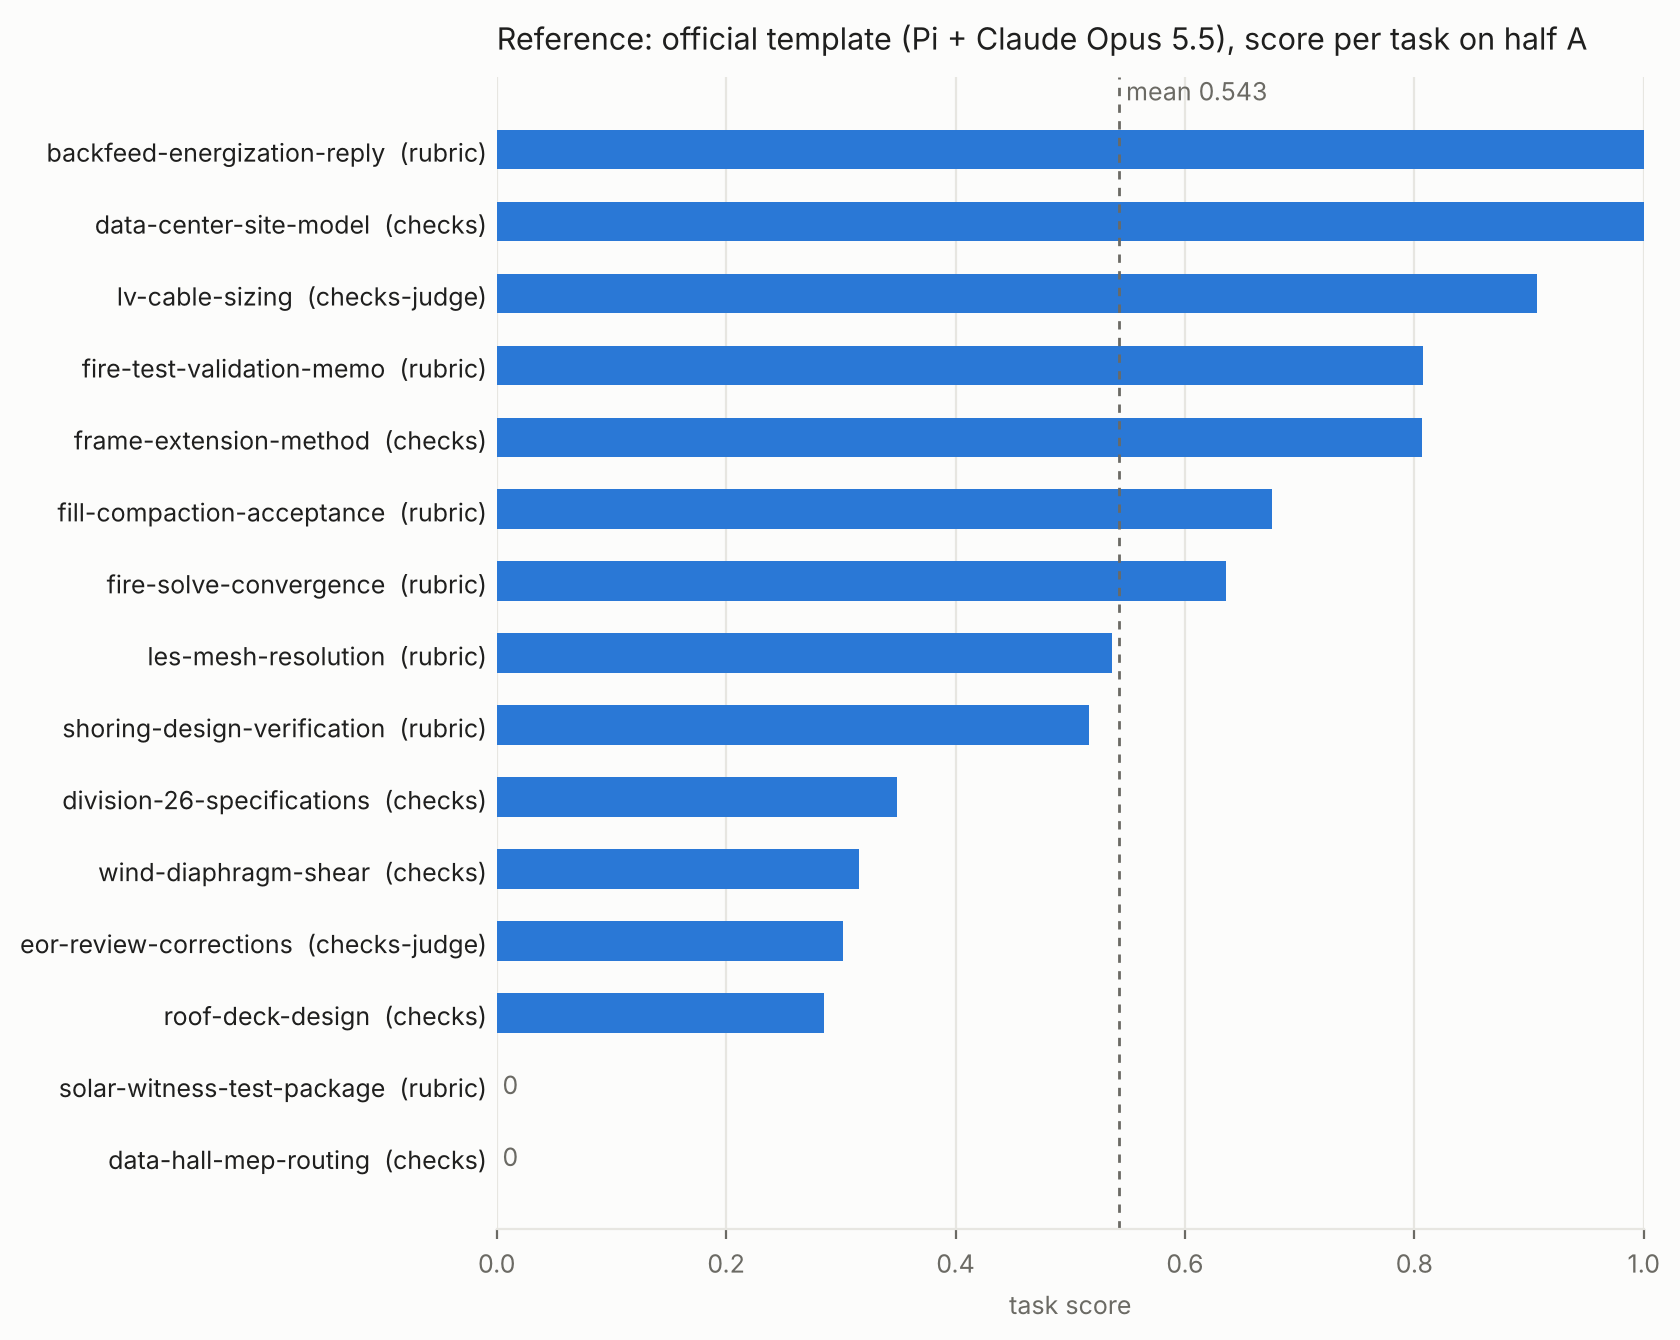

In [6]:
reference = runs[0]
plot_runs([reference["run_id"]], "Reference: official template (Pi + Claude Opus 5.5), score per task on half A");

In [7]:
f = task_frame(reference)
f.groupby("grading")["score"].agg(["mean", "count"]).round(3)

,mean,count
grading,,
checks,0.460,6
checks-judge,0.604,2
rubric,0.596,7


**What stands out**

* A wide spread: two tasks score `1.0`, two score `0`.
* The three structural calculation tasks (wind diaphragm, roof deck, and the EOR corrections)
  all sit around `0.3`.
* One of the zeros, `data-hall-mep-routing`, is a near miss, below.

### A near miss that scored zero

`data-hall-mep-routing` asks for a Python script that builds a clash-free 3D model (IFC) of a data
hall from seven drawing sheets and routes cable tray, busway and chilled-water pipe through it.

We re-graded the template's own deliverable with the task's public grader:

| | template's design | reference route |
|---|---|---|
| connectivity (every row served, every cooling unit reached) | passed | passed |
| total route length | 186.9 m | 260.6 m |
| code-rule violation rate | 8 % | 0 % |
| clashes over 2 mm | **23** | 0 |
| **score** | **0** | 1 |

Every one of the 23 clashes is between two segments **of the same service** overlapping where
they join. Without them the design would have scored about **0.92**. One generic check (no two
solids overlap by more than 2 mm, including pieces of the same route), run before finishing, would
have caught it.

This is the pattern our harness is built around: **the agent defines how its work will be
judged, checks its work against that before finishing, and fixes what fails.**

## 6. The ladder: build up from the floor

We add one capability at a time, each motivated by a failure we observe, measuring every step on
half A.

| Rung | Harness | Question it answers |
|---|---|---|
| 0 | **one model call**: files pasted in as plain text, deliverables written from the reply | how far does one careful read of the project get? |
| 1 | a tool loop: read files, run commands, write files | how much does access to the project add? |
| ... | each next capability is chosen from what rung *n* got wrong | |

Rung 1 is chosen after we have read rung 0's failures task by task.

## Lab log

Dated, honest notes, including what went wrong. Newest last.

* **2026-11-25.** Docker on the Mac is too small, so runs move to a cloud VM. Budget and hard cap
  set up. Claude Opus 5.5 has zero Vertex quota (three increase requests auto-denied), so the dev
  judge is Gemini 4 Neon.
* **2026-11-25.** The Mac broke. A GitHub Actions workflow now drives the VM from a cloud session.
  First attempts failed on small things (a service-account name too short, a lookup that needed
  admin rights).
* **2026-11-26.** The Hugging Face token never reached the VM (it was empty), and two of our own
  checks reported "access OK" when it was not. Replaced with a repository secret and a check that
  tests real access.
* **2026-11-26.** First rung-0 start: the 29-task dataset (16,425 files) downloaded in 28 minutes
  through Hugging Face's rate limit, then the run stopped because the model proxy was not running
  after the VM's reboot. The run script now starts the proxy if it is down.
* **2026-11-26.** Review of `harnesses/naive` found that a reply cut off at the token limit
  silently lost its last file. Fixed in the harness (the partial file is now written and the cut-off
  is logged); rung 0's first runs predate that fix, which matters only for tasks where the reply
  was cut off.